In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
sns.set_theme(style="whitegrid")

from qss.solver_options import brent_defaults, sa_defaults
from qss.chemical_potential import chemical_potential
from qss.distributions import DistType, prepare_2D_lattice_data
import tools.scientific_plot as sp


In [2]:
MU_B  = 5.788381806e-5# eV/T
N = 100
t = -1
t_prim = 0.25
# t_prim = 0

kx = np.linspace(-np.pi, np.pi, N, endpoint=False)
ky = np.linspace(-np.pi, np.pi, N, endpoint=False)
e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

In [3]:
# Band filling values
n_min = 0.01
n_max = 0.99
n_count = 40

# Magnetic field values
Ha_min = -1
Ha_max = 2
Ha_count = 30

# Beta values

beta_min = -2
beta_max = 3
beta_count = 5

distros = [DistType.FD, DistType.FLB, DistType.NFL, DistType.NFLB, DistType.SSL]  # ND
# n  = np.array([0.5, 0.8, 0.9], dtype=np.float64)  # NN
n  = np.linspace(n_min, n_max, n_count, dtype=np.float64)  # NN
# beta = np.array([0.1, 1.0], dtype=np.float64)  # NB
beta = np.logspace(beta_min, beta_max, beta_count, dtype=np.float64)  # NB
# H_a = np.array([0.0], dtype=np.float64) # NH
H_a = np.logspace(Ha_min, Ha_max, Ha_count, dtype=np.float64) # NH
H_a = np.concat([np.array([0.0]), H_a])

In [4]:
n =np.array([0.01] + [0.025 + 0.025 * x for x in range(39)] + [0.99])
beta= list(np.logspace(-2,3,61))
beta.append(0.2)
beta.append(np.inf)
beta = np.sort(beta)
beta = np.round(beta, 4)

In [5]:
py_opts = brent_defaults(
    abs_tol=1e-9, 
    rel_tol=1e-6, 
    expand_factor=1.4,
    initial_step=10.0,  
    max_expands=64,
    max_iters=500      
)
native_opts= py_opts.to_qss()

In [6]:
# py_opts = sa_defaults(T0=5e3,
#                       T_min=1e-8,
#                       alpha=0.95,
#                       max_iters=1e6,
#                       min_iters = 85,
#                       stall_iters=65,
#                       step_decay=0.95,
#                       step_sigma=2.15,
#                       bounds=[(-3., 3.)]
#                       )
# native_opts= py_opts.to_qss()

In [7]:
mu = Path("chemical_potential_results.csv")
if  mu.exists():
    mu_df = pd.read_csv(mu)
    n = np.unique(mu_df["n"])
    distro = np.unique(mu_df["distro"])
    k_BT = np.unique(mu_df["k_BT"])
    beta = 1/k_BT
    H_a = np.unique(mu_df["H_a"])
    mu_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])

else:
    mu_df = chemical_potential(
        distros=distros,
        n_vals=n,
        beta_vals=beta,
        H_a_vals=H_a,
        N=N,
        E=e_k,
        solver_opts=native_opts,
        x0=10.,
        a0=-5.0,
        b0=5.0,
    )
    k_BT = 1/beta
    mu_df.to_csv("chemical_potential_results.csv")
mu_df

mu  iterations  converged      residual
distro n     k_BT  H_a                                                   
FD     0.010 100.0 0.0   -529.341704          23       True  8.402876e-09
       0.025 100.0 0.0   -436.955871          23       True  2.898080e-08
       0.050 100.0 0.0   -366.366798          20       True  2.611124e-08
       0.075 100.0 0.0   -324.529714          23       True  3.651008e-09
       0.100 100.0 0.0   -294.454038          23       True  1.448324e-08
...                              ...         ...        ...           ...
SSL    0.900 0.0   100.0    2.126061          24       True  1.000000e-04
       0.925 0.0   100.0    2.335492          26       True  1.000000e-04
       0.950 0.0   100.0    2.544645          24       True  1.000000e-04
       0.975 0.0   100.0    2.769320          22       True  1.000000e-04
       0.990 0.0   100.0    2.905804          21       True  1.000000e-04

[400365 rows x 4 columns]



In [13]:
# Select a magnetic field to plot
H_a_plot = H_a[1]
beta_plot = beta

# Plotimport scientific_plot as sp
sp.plot_result_n(
    results=mu_df,
    n=n,
    betas=beta_plot,
    y_label=r"chemical potential, $\mu / k_B N$",
    distros=distros,
    H_a=H_a_plot,
    y_col="mu",  # Specify the column to plot
    legend_position="center left",
    figsize=(8, 5),
    cols=2 # Adjust columns for layout
    
)
plt.show()

<Figure size 640x480 with 0 Axes>

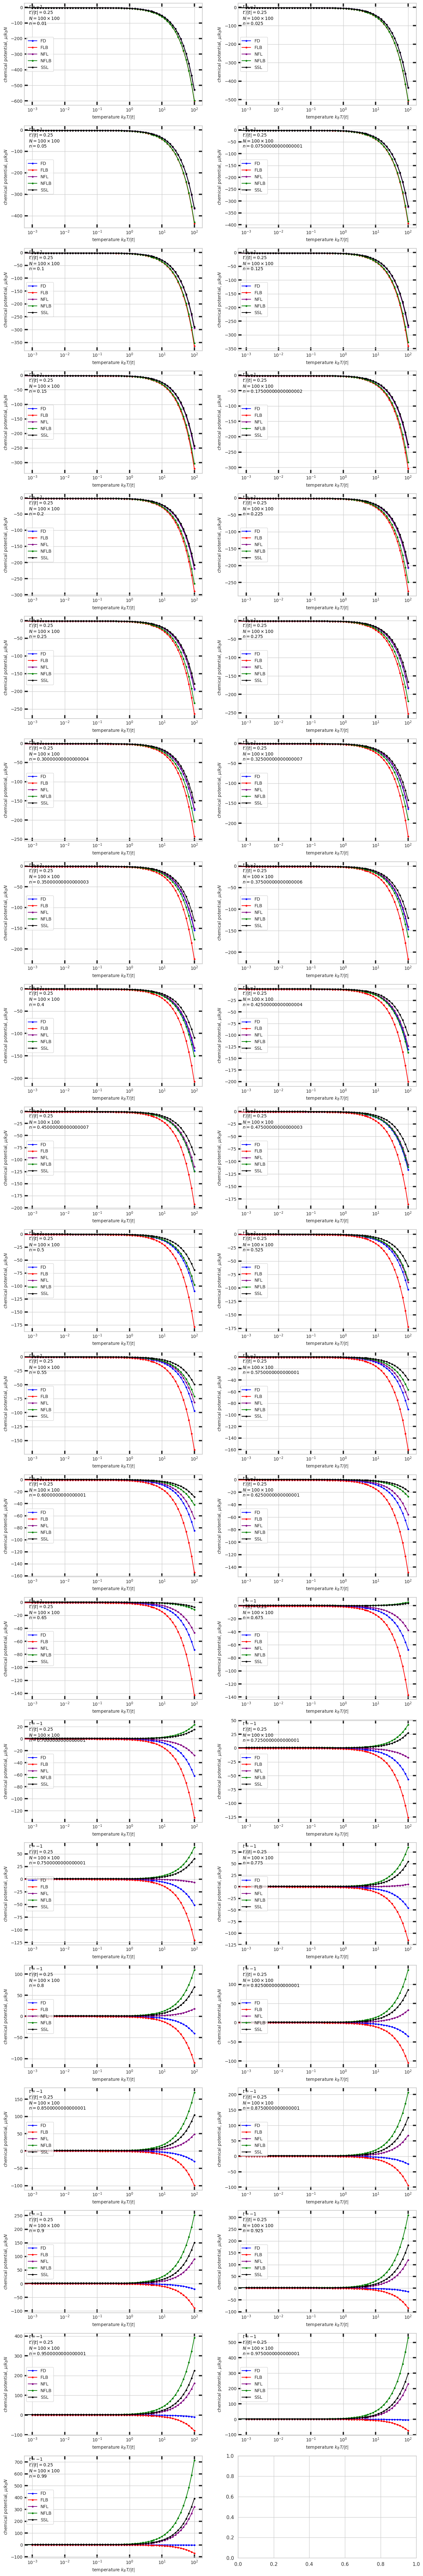

In [14]:
n_plot = n
H_a_plot = H_a[0]

# Plotimport scientific_plot as sp
sp.plot_results_temperature(
    results=mu_df,
    n=n_plot,
    betas=beta,
    y_label=r"chemical potential, $\mu / k_B N$",
    distros=distros,
    H_a=H_a_plot,
    y_col="mu",  # Specify the column to plot
    legend_position="center left",
    figsize=(8, 5),
    cols=2 # Adjust columns for layout
)
plt.show()

<Figure size 640x480 with 0 Axes>

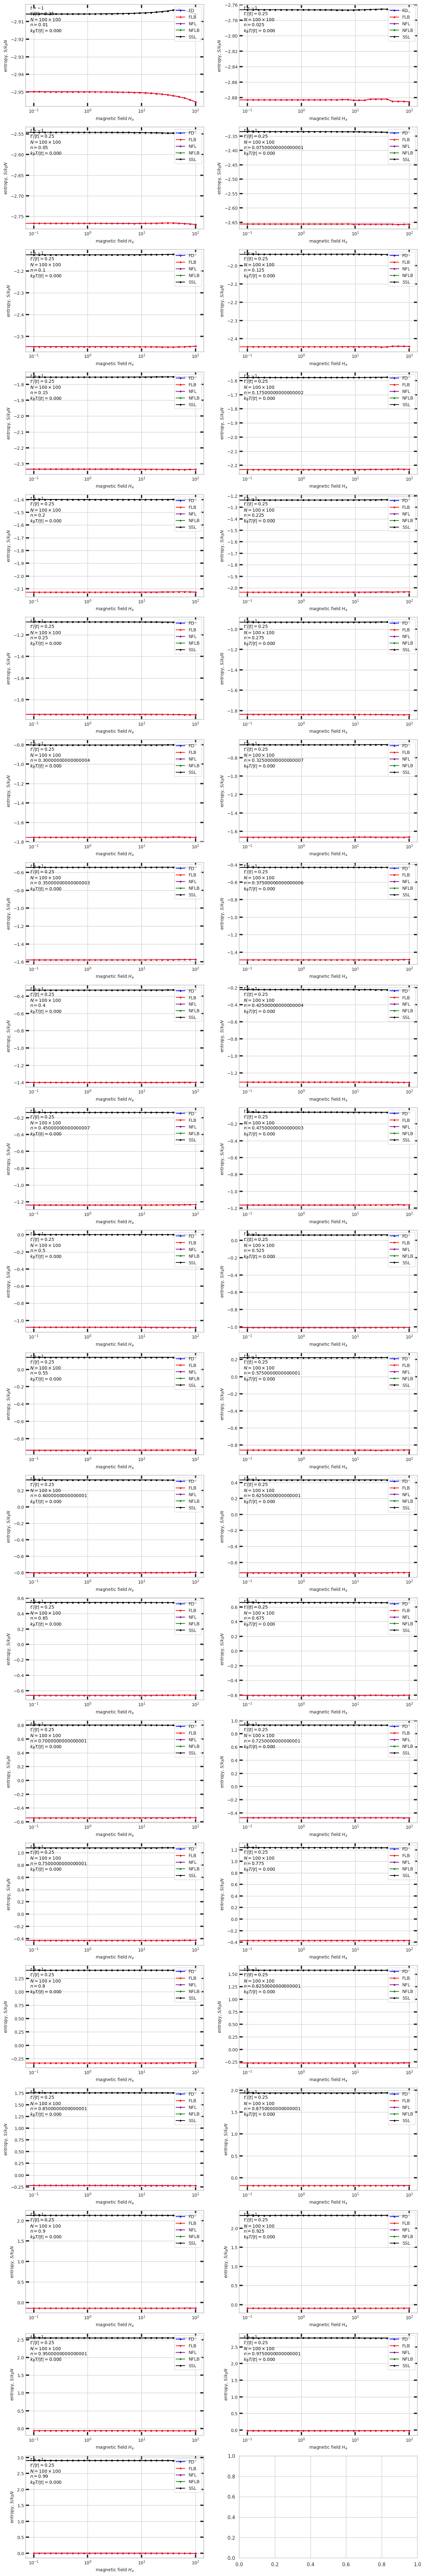

In [16]:
n_plot = n
beta_plot = beta[20]
sp.plot_results_Ha(
    results=mu_df,
    n=n_plot,          # List of n values to create subplots for
    beta=beta[-1],     # Fixed beta value
    y_label=r"entropy, $S / k_B N$",
    distros=distros,
    y_col="mu",
    legend_position="upper right",
    figsize=(8, 5),
    cols=2,
    # ylims=(-200, -60)
)
plt.show()

In [17]:
# Example: Plot Entropy vs Temperature (k_BT) and Magnetic Field (H_a)
# for different band fillings (n)

# Select a few n values for the rows
n_rows = [n[0], n[len(n)//2]] 
sp.plot_3d_results_interactive(
    results=mu_df,
    row_param="H_a",       # Vary n across rows
    row_vals=H_a[:2],     # Specific n values
    x_param="k_BT",      # X axis
    y_param="n",       # Y axis
    z_label=r"$S / k_B N$",
    z_col="mu",          # or "entropy" if you have calculated it
    distros=distros,
    # figsize=(15, 10)
)
plt.show()

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed